## scMAVERICS - multiome integration

The word integration is used a lot in single cell analysis. In this context, multiome integration really means the combining of gene expression and chromatin accessibility modalities across all samples in a dataset. The resulting object at the end of this processing step will be the final object from which all multiome analyses can be based. For analysis specific to chromatin accessibility peaksets unique to cell types and/or diagnosis state binning, proceed to the next section [Peak calling](peaks.md).

**🚨 HALT! 🚨**

This section assumes you have completed the previous section, [snRNAseq preprocessing](snRNAseq.md) and [snATACseq preprocessing](snATACseq.md), with the object `06_QC_filtered_anndata_rna.h5ad` and `04_modeled_anndata_atac.h5ad` in the `atlas` folder. If not, go back and complete the analysis, preferably with the Snakemake pipeline.

## Package and data loading

In [2]:
import gc
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import muon as mu
import snapatac2 as snap
import scipy.sparse as sp
import scvi
import pychromvar as pc
from pyjaspar import jaspardb

import matplotlib.pyplot as plt

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/muon/_core/preproc.py:32: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


### Define working and data directories

In [3]:
data_dir = '/data/CARD_singlecell/Brain_atlas/SN_Multiome/'
work_dir = '/data/CARD_singlecell/SN_atlas/' 

### Load metadata

As stated before, metadata should be imported, for visualizing parameters, 

In [4]:
metadata_df = pd.read_csv(work_dir + 'input/metadata.csv')
metadata_df

,Sample_ID,Use_batch,Age,PMI,Sex,Brain_bank,Primary Diagnosis
0,6178,6,68,22.5,Male,Human Brain and Spinal Fluid Resource Center,control
1,3284,1,78,11.5,Female,Human Brain and Spinal Fluid Resource Center,control
2,6384,3,50,22.3,Female,Human Brain and Spinal Fluid Resource Center,PD
3,5638,3,77,19.3,Male,Human Brain and Spinal Fluid Resource Center,PD


In [5]:
# Define keys
sample_key = 'Sample_ID'
batch_key = 'Use_batch'

# Define list of samples
samples = metadata_df[sample_key].astype(str)
batches = metadata_df[batch_key]
# Ensure sample names are strings
metadata_df[sample_key] = metadata_df[sample_key].astype(str)

# Latent space parameters
high_var_gene_num = 2000
high_var_peak_num = 20000
random_number_seed = 0
max_epoch = 1000
machine_type = 'cpu' # mps if you are running this on a Mac with a metal cpu

## Creating the multiome object

### multiome_merge

MuData objects are similar to AnnData objects, where

In [7]:
# Read in RNA dataset
rna = sc.read_h5ad(work_dir + '/atlas/06_QC_filtered_anndata_rna.h5ad')

# Read in ATAC dataset
atac = sc.read_h5ad(work_dir + '/atlas/04_modeled_anndata_atac.h5ad')

In [8]:
# Create the anndata object
mdata = mu.MuData({"rna": rna, "atac": atac})

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


In [9]:
# Create sample key for batch-corrected MultiVI
mdata.obs[sample_key] = [(x.split('-1_')[1]) for x in mdata.obs_names]
mdata.obs

,rna:n_genes_by_counts,rna:total_counts,rna:total_counts_rb,rna:pct_counts_rb,rna:total_counts_mt,rna:pct_counts_mt,rna:Sample_ID,rna:Use_batch,rna:Age,rna:PMI,...,rna:G2M_score,rna:phase,rna:doublet_score,rna:predicted_doublet,rna:leiden,rna:celltype,atac:sample,atac:n_fragment,atac:tsse,Sample_ID
CTCCAACTCTTGCAAA-1_6178,11969,107576,3301,3.068528,5262,4.891426,6178,6,68,22.5,...,-1.098352,G1,0.089721,False,0,EC,6178,343949,17.177150,6178
ACAGGATCACAACCTA-1_6178,7406,25161,222,0.882318,43,0.170899,6178,6,68,22.5,...,-0.610256,G1,0.135907,False,1,OPC,6178,305398,13.918937,6178
CATAGACTCGATTATG-1_6178,13373,192511,433,0.224922,66,0.034284,6178,6,68,22.5,...,-3.405861,G1,0.063946,False,2,DaN,6178,166685,6.673376,6178
TCGTTTCCAATGCCTA-1_6178,7726,28196,99,0.351114,44,0.156051,6178,6,68,22.5,...,-0.613095,G1,0.078507,False,3,Astro,6178,232259,14.794874,6178
GTATGTTCAAGGACCA-1_6178,7649,28033,108,0.385260,50,0.178361,6178,6,68,22.5,...,-0.550458,G1,0.051028,False,3,Astro,6178,163141,16.353665,6178
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTGGCACGTTACA-1_5638,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,NaN,<NA>,NaN,NaN,5638,9825,11.113956,5638
TTTGTGGCATGAATAG-1_5638,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,NaN,<NA>,NaN,NaN,5638,14257,20.888272,5638
TTTGTGTTCAAGCGCC-1_5638,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,NaN,<NA>,NaN,NaN,5638,20794,5.329154,5638
TTTGTGTTCACGCGGT-1_5638,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,...,NaN,NaN,NaN,<NA>,NaN,NaN,5638,1569,21.080369,5638


### multiome_feature_selection

#### Gene expression layer

In [10]:
# Select for the most variable genes
sc.pp.highly_variable_genes(
    rna, 
    n_top_genes=high_var_gene_num,
    subset=False,
    flavor = 'seurat_v3')
# Make a copy that only contains the highly variable genes
rna_hvg = rna[:, rna.var['highly_variable']].copy()
rna_hvg

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)


AnnData object with n_obs × n_vars = 23019 × 2000
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_rb', 'pct_counts_rb', 'total_counts_mt', 'pct_counts_mt', 'Sample_ID', 'Use_batch', 'Age', 'PMI', 'Sex', 'Brain_bank', 'Primary Diagnosis', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'predicted_doublet', 'leiden', 'celltype'
    var: 'gene_ids', 'mt', 'rb', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'celltype_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'umap'
    obsm: 'X_scvi', 'X_umap', 'padj_ulm', 'score_ulm'
    layers: 'counts', 'cpm', 'log-norm'
    obsp: 'connectivities', 'distances'

In [11]:
# Verify the RNA layer is using counts (this is important for MultiVI)
if "counts" in rna_hvg.layers:
    rna_hvg.X = rna_hvg.layers["counts"].copy()

#### Chromatin accessibility layer

In [12]:
# Select for the most variable peaks
snap.pp.select_features(atac, n_features=high_var_peak_num, inplace=True)
# Make a copy that only contains the highly variable peaks
atac_hvp = atac[:, atac.var["selected"].values].copy()
atac_hvp

2026-11-03 18:42:19 - INFO - Selected 20000 features.


AnnData object with n_obs × n_vars = 34934 × 20000
    obs: 'sample', 'n_fragment', 'tsse'
    var: 'count', 'selected'
    uns: 'spectral_eigenvalue'
    obsm: 'X_spectral', 'X_umap'
    obsp: 'distances'

In [13]:
# Save modality specific barcodes
rna_barcodes = rna_hvg.obs_names
atac_barcodes = atac_hvp.obs_names

# Find the paired, RNA-, and ATAC-only barcodes
all_barcodes = rna_barcodes.union(atac_barcodes, sort=False)
paired_barcodes = rna_barcodes.intersection(atac_barcodes, sort=False)
rna_only_barcodes = rna_barcodes.difference(atac_barcodes, sort=False)
atac_only_barcodes = atac_barcodes.difference(rna_barcodes, sort=False)

print(f'{len(paired_barcodes)} paired nuclei')
print(f'{len(rna_only_barcodes)} nuclei with only gene expression')
print(f'{len(atac_only_barcodes)} nuclei with only chromatin accessibility')

20672 paired nuclei
2347 nuclei with only gene expression
14262 nuclei with only chromatin accessibility


In [14]:
# Keep original RNA object; only create missing rows for ATAC-only nuclei
rna_missing = ad.AnnData(
    X=sp.csr_matrix((len(atac_only_barcodes), rna_hvg.n_vars), dtype=rna_hvg.X.dtype),
    obs=pd.DataFrame(index=atac_only_barcodes),
    var=rna_hvg.var.copy()
)

In [15]:
# Keep original ATAC object; only create missing rows for RNA-only nuclei
atac_missing = ad.AnnData(
    X=sp.csr_matrix((len(rna_only_barcodes), atac_hvp.n_vars), dtype=atac_hvp.X.dtype),
    obs=pd.DataFrame(index=rna_only_barcodes),
    var=atac_hvp.var.copy()
)

#### MuData object ready for MultiVI

In [16]:
# Create RNA and ATAC objects that have the same index, missing values
# will be filled the 'rna/atac_missing' objects
unified_rna = ad.concat([rna_hvg, rna_missing], merge="same")
unified_atac = ad.concat([atac_missing, atac_hvp], merge="same")

# Ensure only the nuclei with paired barcodes are included
unified_rna = unified_rna[all_barcodes, :]
unified_atac = unified_atac[all_barcodes, :]

# Create the object
hv_mdata = mu.MuData({"rna": unified_rna, "atac": unified_atac})

/tmp/ipykernel_1641455/3460503119.py:3: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  unified_rna = ad.concat([rna_hvg, rna_missing], merge="same")
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_ob

In [17]:
# Metadata for plotting
paired_set = set(paired_barcodes)
rna_only_set = set(rna_only_barcodes)
atac_only_set = set(atac_only_barcodes)
hv_mdata.obs["modality_group"] = pd.Categorical(
    [
        "paired" if x in paired_set else
        "rna_only" if x in rna_only_set else
        "atac_only"
        for x in mdata.obs_names
    ],
    categories=["paired", "rna_only", "atac_only"]
)

In [18]:
# Create sample key for batch-corrected MultiVI
hv_mdata.obs[sample_key] = [(x.split('-1_')[1]) for x in hv_mdata.obs_names]
# Update object
hv_mdata = hv_mdata.copy()
# Save object
hv_mdata

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


MuData object with n_obs × n_vars = 37281 × 22000
  obs:	'modality_group', 'Sample_ID'
  2 modalities
    rna:	37281 × 2000
      var:	'gene_ids', 'mt', 'rb', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    atac:	37281 × 20000
      var:	'count', 'selected'

This result is an object with paired nuclei values for both modalities, where the are null values for nuclei in either modality that do not pass QC thresholds.

## Modeling

### multiome_model

In [19]:
scvi.settings.seed = int(random_number_seed)

INFO: [rank: 0] Seed set to 0
2026-11-03 18:42:21 - INFO - [rank: 0] Seed set to 0


In [20]:
# Setup SCVI on the data layer
scvi.model.MULTIVI.setup_mudata(
    hv_mdata,
    batch_key=sample_key,
    modalities={
        "rna_layer": "rna",
        "atac_layer": "atac"
    }
)

In [22]:
# Train
mvi_model = scvi.model.MULTIVI(
    hv_mdata,
    n_genes=hv_mdata.mod["rna"].n_vars,
    n_regions=hv_mdata.mod["atac"].n_vars,
)

mvi_model.train(
    accelerator='cpu',
    max_epochs=max_epoch,
    lr=1e-3,
    early_stopping=True,
    batch_size=256
)

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/torch/nn/modules/linear.py:124: UserWarning: Initializing zero-element tensors is a no-op
  init.kaiming_uniform_(self.weight, a=math.sqrt(5))
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /data/catchingba/.conda/envs/multiome/lib/python3.11 ...
INFO: GPU available: False, used: False
2026-11-03 18:45:31 - INFO - GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
2026-11-03 18:45:31 - INFO - TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning E

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Monitored metric reconstruction_loss_validation did not improve in the last 50 records. Best score: 4787.161. Signaling Trainer to stop.


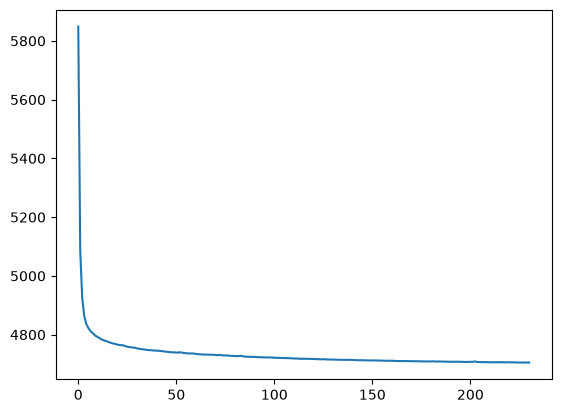

In [23]:
elbo = mvi_model.history['elbo_train']
elbo['elbo_validation'] = mvi_model.history['elbo_validation']

plt.plot(elbo['elbo_train'])

### multiome_latent_transfer

In [24]:
# Convert the cell barcode to the observable matrix X_scvi which neighbors and UMAP can be calculated from
mdata.obsm['X_multivi'] = mvi_model.get_latent_representation()

In [30]:
mdata.obs["modality_group"] = hv_mdata.obs["modality_group"]

In [25]:
# Calculate nearest neighbors and the UMAP from the X_scvi observable matrix
sc.pp.neighbors(mdata, use_rep='X_multivi')
sc.tl.umap(mdata, min_dist=0.3)

In [26]:
# Calculate the leiden distance from the nearest neighbors, use a couple resolutions
sc.tl.leiden(mdata, key_added='leiden', flavor = 'igraph')

In [27]:
# Transfer leiden clusters to rna and atac modalities
barcode2leiden = mdata.obs['leiden'].to_dict()
mdata.mod['rna'].obs['leiden'] = [barcode2leiden[x] for x in mdata.mod['rna'].obs_names]
mdata.mod['atac'].obs['leiden'] = [barcode2leiden[x] for x in mdata.mod['atac'].obs_names]

... storing 'Sample_ID' as categorical


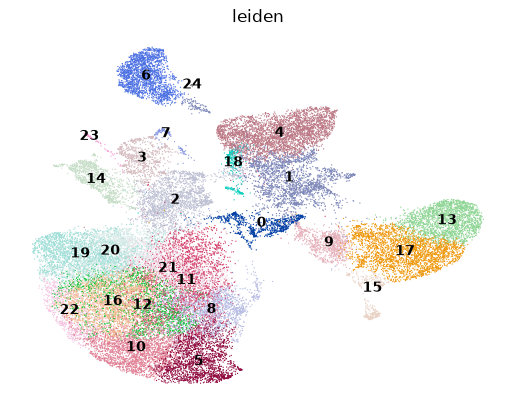

In [32]:
mu.pl.umap(
    mdata,
    color = ['leiden'],
    frameon = False,
    legend_loc = 'on data'
)

... storing 'Sample_ID' as categorical


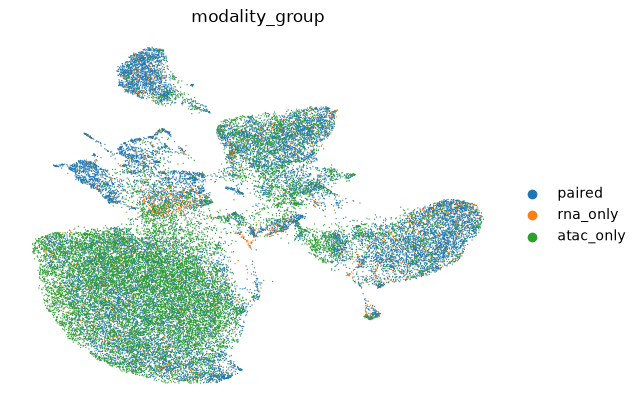

In [33]:

mu.pl.umap(
    mdata,
    color = ['modality_group'],
    frameon = False,
)

## Annotation

### multiome_cell_type_annotation

In [1]:
mdata = mu.read_h5mu(work_dir + 'data/08_multiome.h5mu')

NameError: name 'mu' is not defined

In [34]:
mdata.write_h5mu(work_dir + 'data/08_multiome.h5mu', compression = 'gzip')

... storing 'Sample_ID' as categorical
... storing 'leiden' as categorical
... storing 'leiden' as categorical
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join

### multiome_pychromvar